In [4]:
# 1. تثبيت المكتبات الأساسية (بما فيها أحدث نسخة من YOLO)
!pip install roboflow pyyaml matplotlib ultralytics opencv-python numpy pandas

import os
from roboflow import Roboflow

# 2. تعيين الـ API Key الخاص بك
rf = Roboflow(api_key="YOUR_API_KEY_HERE")

print("⏳ جاري تحميل الـ 5 داتا سيتس محلياً على جهازك...")
print("-" * 60)

# الداتا الأولى
project_1 = rf.workspace("btech-rpmod").project("road-house")
dataset_1 = project_1.version(14).download("yolov11")
if os.path.exists(dataset_1.location): os.rename(dataset_1.location, "dataset_1_road_house")

# الداتا الثانية
project_2 = rf.workspace("safewalkbd-7jrsx").project("safewalkbd-final")
dataset_2 = project_2.version(30).download("yolov11")
if os.path.exists(dataset_2.location): os.rename(dataset_2.location, "dataset_2_safewalkbd")

# الداتا الثالثة
project_3 = rf.workspace("kailuns-workspace-bhemq").project("smart-glasses-system")
dataset_3 = project_3.version(1).download("yolov11")
if os.path.exists(dataset_3.location): os.rename(dataset_3.location, "dataset_3_smart_glasses")

# الداتا الرابعة
project_4 = rf.workspace("project-uyx6c").project("outdoor-detection-model")
dataset_4 = project_4.version(3).download("yolov11")
if os.path.exists(dataset_4.location): os.rename(dataset_4.location, "dataset_4_outdoor")

# الداتا الخامسة
project_5 = rf.workspace("groups-workspace-pnea4").project("object-det-prrw9")
dataset_5 = project_5.version(2).download("yolov11")
if os.path.exists(dataset_5.location): os.rename(dataset_5.location, "dataset_5_object_det")

print("\n✅ تم تحميل الـ 5 داتا سيتس وتسميتها بنجاح!")

C:\Users\Andalus\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.3)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


⏳ جاري تحميل الـ 5 داتا سيتس محلياً على جهازك...
------------------------------------------------------------
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Road-House-14 in yolov11:: 100%|██████████| 33203/33203 [00:10<00:00, 3217.26it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SafeWalkBD-Final-30 in yolov11:: 100%|██████████| 49469/49469 [00:16<00:00, 2932.86it/s]


loading Roboflow workspace...
loading Roboflow project...


... (3 outputs left out)

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to Object-Det-2 in yolov11:: 100%|██████████| 73343/73343 [00:20<00:00, 3504.51it/s]



✅ تم تحميل الـ 5 داتا سيتس وتسميتها بنجاح!


In [5]:
import os
import shutil
import random
import yaml
from collections import Counter

# 1. القائمة الموحدة والنهائية
FINAL_CLASSES = {
    0: "Crosswalk", 1: "Edge_Sidewalk", 2: "Opened_Door", 3: "Traffic_Light",
    4: "Obstacle", 5: "Vehicle", 6: "Person", 7: "Pole_Bollard", 8: "Pothole",
    9: "Stairs", 10: "Animal", 11: "Cane"
}

# 2. خرائط التحويل (Mapping)
map_d1 = {0:0, 1:1, 2:2, 3:3, 11:3, 4:4, 5:5, 12:5, 6:6, 7:7, 8:8, 10:9}
map_d2 = {1:0, 9:1, 11:3, 2:4, 8:4, 13:5, 15:5, 4:6, 5:7, 6:8, 10:9, 0:10}
map_d3 = {0:4, 4:4, 12:4, 1:5, 3:5, 13:5, 2:7, 8:7, 5:2, 6:6, 7:1, 10:1, 9:8, 11:9}
map_d4 = {1:0, 6:1, 8:3, 2:4, 5:4, 9:4, 10:5, 3:6, 4:7, 0:10, 7:9}
map_d5 = {24:3, 29:3, 1:4, 3:4, 8:4, 31:4, 4:5, 5:5, 6:5, 17:5, 30:5, 32:5, 20:8, 23:9, 7:10, 9:10, 11:6, 12:6, 15:11}

final_distribution = Counter()
OUTPUT_DATASET = "Blind_Navigation_Dataset" # المسار المحلي

def merge_and_filter_dataset(src_base, dest_base, mapping, dataset_name, split="train"):
    src_img_dir = os.path.join(src_base, split, "images")
    src_lbl_dir = os.path.join(src_base, split, "labels")
    dest_img_dir = os.path.join(dest_base, split, "images")
    dest_lbl_dir = os.path.join(dest_base, split, "labels")

    os.makedirs(dest_img_dir, exist_ok=True)
    os.makedirs(dest_lbl_dir, exist_ok=True)

    if not os.path.exists(src_lbl_dir): return 0

    copied_images = 0
    img_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']

    for label_file in os.listdir(src_lbl_dir):
        if not label_file.endswith('.txt'): continue

        with open(os.path.join(src_lbl_dir, label_file), 'r') as f:
            lines = f.readlines()

        new_lines = []
        has_rare_class = False
        has_heavy_class = False
        temp_counts = []

        for line in lines:
            parts = line.split()
            if not parts: continue
            old_id = int(parts[0])

            if old_id in mapping:
                new_id = mapping[old_id]
                parts[0] = str(new_id)
                new_lines.append(" ".join(parts) + "\n")
                temp_counts.append(new_id)

                if new_id in [5, 6]: has_heavy_class = True
                if new_id in [0, 2, 8, 9, 10, 11]: has_rare_class = True

        if new_lines:
            # 💡 منطق الاتزان الفائق: لو الصورة فيها عربيات/أشخاص بس، هنحتفظ بـ 15% منها فقط
            if split == "train" and has_heavy_class and not has_rare_class:
                if random.random() > 0.15: continue

            base_name = os.path.splitext(label_file)[0]
            img_file = None
            for ext in img_extensions:
                if os.path.exists(os.path.join(src_img_dir, base_name + ext)):
                    img_file = base_name + ext
                    break

            if img_file:
                with open(os.path.join(dest_lbl_dir, label_file), 'w') as f:
                    f.writelines(new_lines)
                shutil.copy(os.path.join(src_img_dir, img_file), os.path.join(dest_img_dir, img_file))
                copied_images += 1

                if split == "train":
                    for n_id in temp_counts:
                        final_distribution[FINAL_CLASSES[n_id]] += 1

    print(f"✅ {dataset_name} ({split}): تم دمج وتصفية {copied_images} صورة.")
    return copied_images

all_datasets = [
    {"path": "dataset_1_road_house", "map": map_d1, "name": "Road House"},
    {"path": "dataset_2_safewalkbd", "map": map_d2, "name": "SafeWalkBD"},
    {"path": "dataset_3_smart_glasses", "map": map_d3, "name": "Smart Glasses"},
    {"path": "dataset_4_outdoor", "map": map_d4, "name": "Outdoor Det"},
    {"path": "dataset_5_object_det", "map": map_d5, "name": "Object Det"}
]

print("⏳ جاري صهر الداتا وتطبيق الموازنة...")
print("-" * 60)
for d in all_datasets:
    if os.path.exists(d["path"]):
        merge_and_filter_dataset(d["path"], OUTPUT_DATASET, d["map"], d["name"], split="train")
        merge_and_filter_dataset(d["path"], OUTPUT_DATASET, d["map"], d["name"], split="valid")
    else:
        print(f"❌ المجلد {d['path']} غير موجود!")

# 3. إنشاء ملف data.yaml بمسار مطلق (Absolute Path) لمنع كراش الويندوز
abs_dataset_path = os.path.abspath(OUTPUT_DATASET)
yaml_content = {
    'path': abs_dataset_path, 
    'train': "train/images",
    'val': "valid/images",
    'nc': len(FINAL_CLASSES),
    'names': list(FINAL_CLASSES.values())
}
with open(os.path.join(OUTPUT_DATASET, "data.yaml"), 'w') as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("\n🎉 تمت العملية! ملف data.yaml جاهز بالمسارات المطلقة لجهازك.")

⏳ جاري صهر الداتا وتطبيق الموازنة...
------------------------------------------------------------
✅ Road House (train): تم دمج وتصفية 9102 صورة.
✅ Road House (valid): تم دمج وتصفية 2679 صورة.
✅ SafeWalkBD (train): تم دمج وتصفية 8626 صورة.
✅ SafeWalkBD (valid): تم دمج وتصفية 4245 صورة.
✅ Smart Glasses (train): تم دمج وتصفية 17676 صورة.
✅ Smart Glasses (valid): تم دمج وتصفية 4537 صورة.
✅ Outdoor Det (train): تم دمج وتصفية 3507 صورة.
✅ Outdoor Det (valid): تم دمج وتصفية 1018 صورة.
✅ Object Det (train): تم دمج وتصفية 12409 صورة.
✅ Object Det (valid): تم دمج وتصفية 1752 صورة.

🎉 تمت العملية! ملف data.yaml جاهز بالمسارات المطلقة لجهازك.


🔍 جاري سحب عينة عشوائية للفحص المرئي...


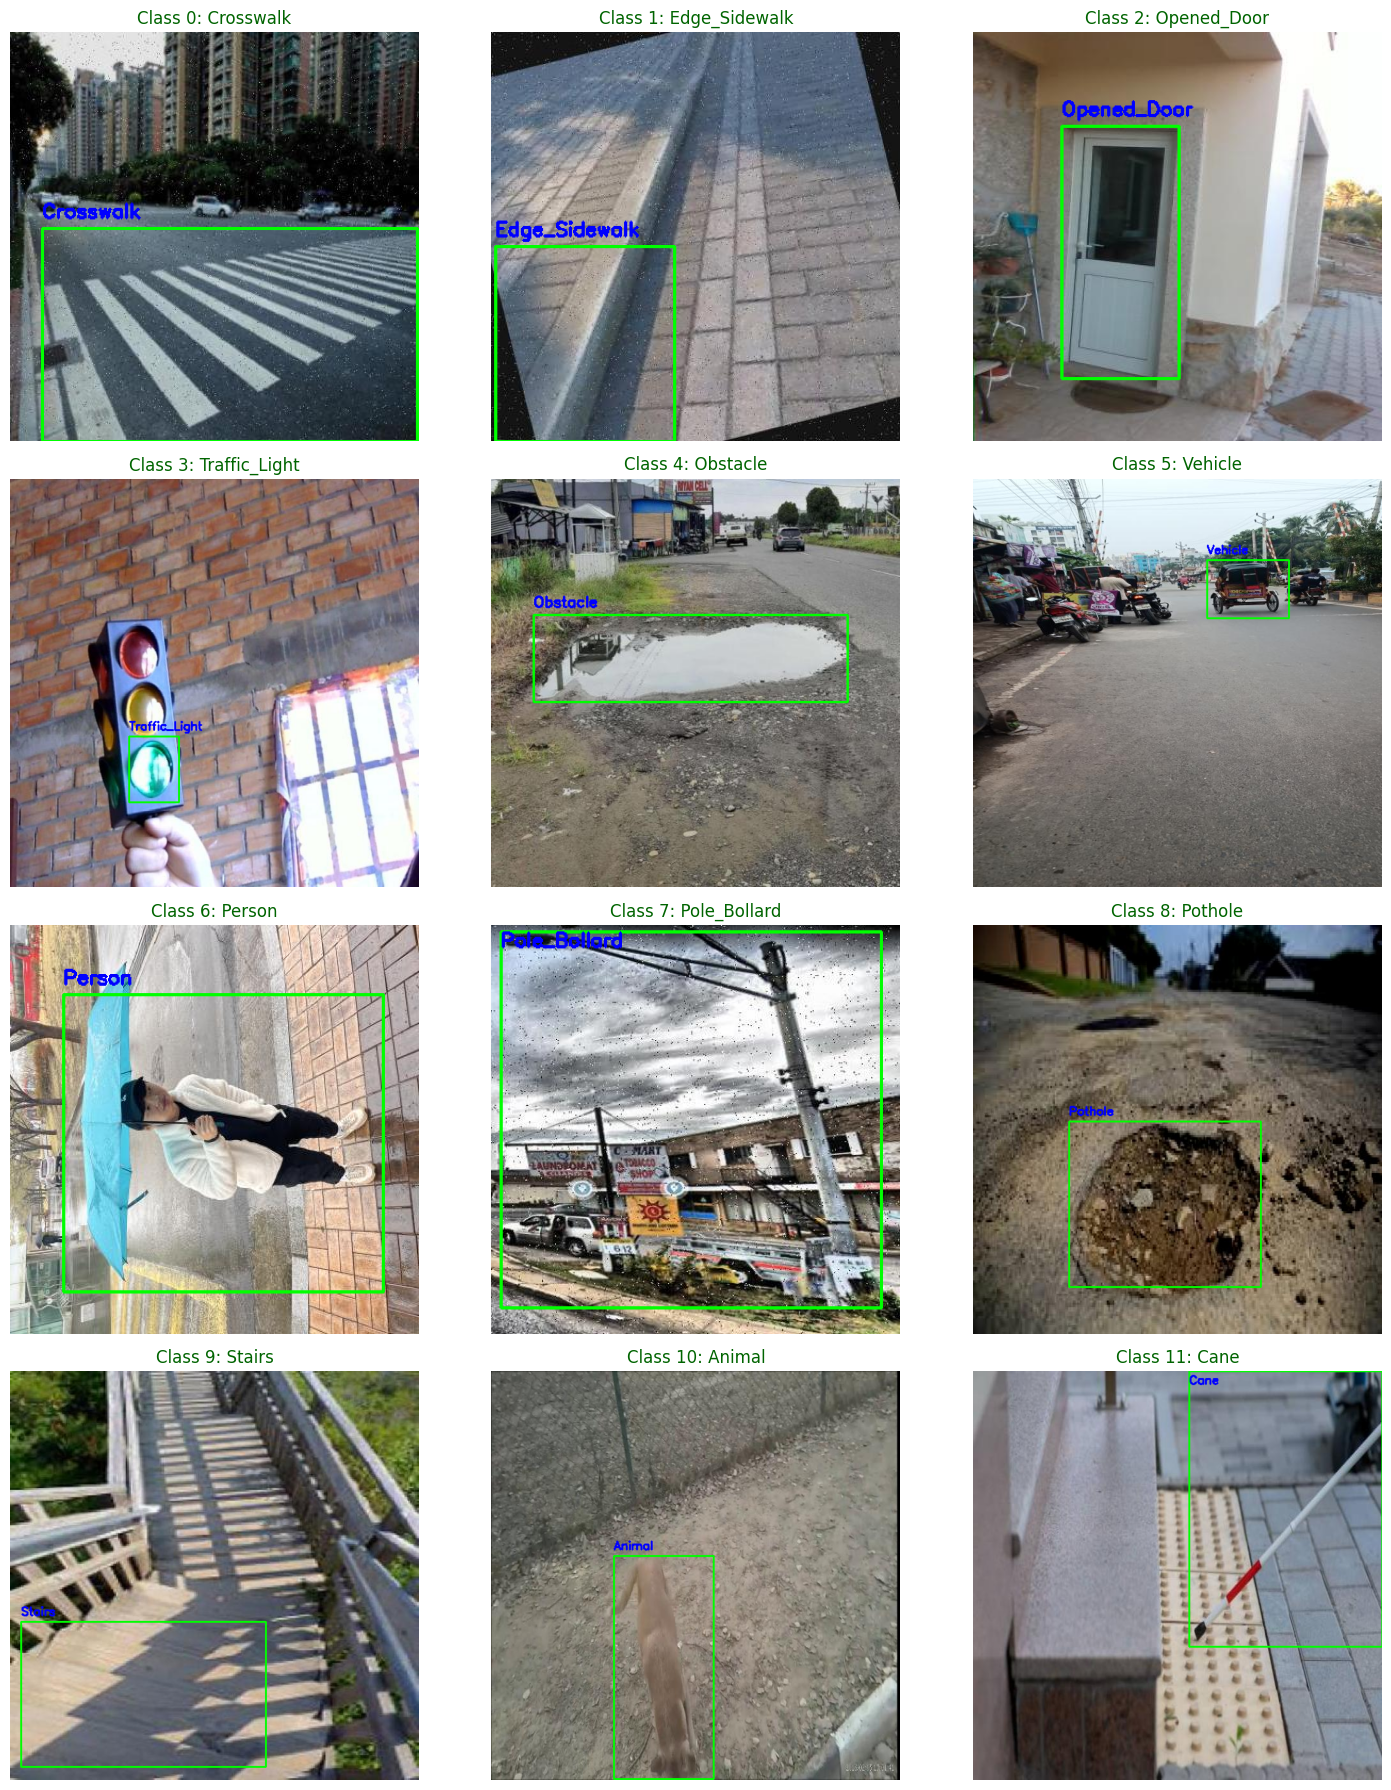

In [6]:
import os
import cv2
import random
import matplotlib.pyplot as plt

DATASET_DIR = "Blind_Navigation_Dataset"
images_dir = os.path.join(DATASET_DIR, "train", "images")
labels_dir = os.path.join(DATASET_DIR, "train", "labels")

FINAL_CLASSES = {
    0: "Crosswalk", 1: "Edge_Sidewalk", 2: "Opened_Door", 3: "Traffic_Light",
    4: "Obstacle", 5: "Vehicle", 6: "Person", 7: "Pole_Bollard", 8: "Pothole",
    9: "Stairs", 10: "Animal", 11: "Cane"
}

def draw_yolo_box(img, box_data, class_name):
    h, w, _ = img.shape
    coords = box_data[1:]
    if len(coords) == 4:
        x_center, y_center, bbox_w, bbox_h = coords
        x1 = int((x_center - bbox_w / 2) * w)
        y1 = int((y_center - bbox_h / 2) * h)
        x2 = int((x_center + bbox_w / 2) * w)
        y2 = int((y_center + bbox_h / 2) * h)
    elif len(coords) > 4:
        xs, ys = coords[0::2], coords[1::2]
        x1, x2 = int(min(xs) * w), int(max(xs) * w)
        y1, y2 = int(min(ys) * h), int(max(ys) * h)
    else:
        return img
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(img, class_name, (x1, max(y1 - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    return img

fig, axes = plt.subplots(4, 3, figsize=(15, 18))
axes = axes.ravel()
img_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']

print("🔍 جاري سحب عينة عشوائية للفحص المرئي...")

for class_id, class_name in FINAL_CLASSES.items():
    found_image = False
    all_label_files = os.listdir(labels_dir) if os.path.exists(labels_dir) else []
    random.shuffle(all_label_files)

    for label_file in all_label_files:
        if not label_file.endswith('.txt'): continue
        with open(os.path.join(labels_dir, label_file), 'r') as f:
            lines = f.readlines()
        target_box = None
        for line in lines:
            parts = line.split()
            if parts and int(parts[0]) == class_id:
                target_box = [float(x) for x in parts]
                break
        if target_box:
            base_name = os.path.splitext(label_file)[0]
            img_path = None
            for ext in img_extensions:
                if os.path.exists(os.path.join(images_dir, base_name + ext)):
                    img_path = os.path.join(images_dir, base_name + ext)
                    break
            if img_path:
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img = draw_yolo_box(img, target_box, class_name)
                    axes[class_id].imshow(img)
                    axes[class_id].set_title(f"Class {class_id}: {class_name}", fontsize=12, color='darkgreen')
                    axes[class_id].axis('off')
                    found_image = True
                    break
    if not found_image:
        axes[class_id].text(0.5, 0.5, f"No image found for\n{class_name}", ha='center', va='center', fontsize=12, color='red')
        axes[class_id].axis('off')

plt.tight_layout()
plt.show()

In [7]:
import os
import torch
from ultralytics import YOLO

# 1. تنظيف كاش كارت الشاشة
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"💻 تم كشف كارت شاشة: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ تحذير: التدريب سيعتمد على المعالج (CPU)، سيستغرق وقتاً طويلاً جداً.")

# 2. إعداد المسارات المحلية بالكامل
project_dir = 'runs/train'
run_name = 'yolov11s_blind_model' 
last_weights_path = os.path.join(project_dir, run_name, 'weights', 'last.pt')
yaml_local_path = os.path.abspath('Blind_Navigation_Dataset/data.yaml')

if os.path.exists(last_weights_path):
    print(f"🔄 تم كشف أوزان سابقة محلياً! جاري الاستكمال...")
    model = YOLO(last_weights_path)
    results = model.train(resume=True)
else:
    print("🚀 جاري بدء تدريب جديد بموديل YOLO11s (Small)...")
    
    # الاعتماد على الموديل الـ Small
    model = YOLO('yolo11s.pt') 

    results = model.train(
        data=yaml_local_path, 
        epochs=100,
        imgsz=640,            
        device=0 if torch.cuda.is_available() else 'cpu',
        patience=15,          
        
        # 💡 إعدادات مخصصة لأجهزة الكمبيوتر العادية (Local PCs)
        batch=16,             # تم تحديد الباتش لـ 16 لتفادي رسالة Out of Memory
        amp=True,             
        workers=2,            # تم تقليل الـ workers لـ 2 عشان الويندوز ميتجمدش
        cache=False,          # قفلنا الكاش عشان ميستهلكش كل الرامات
        
        optimizer='AdamW',    
        lr0=0.01,             
        plots=True,           
        
        project=project_dir,
        name=run_name,
        
        flipud=0.0,           
        fliplr=0.5,           
        mixup=0.1             
    )

💻 تم كشف كارت شاشة: NVIDIA GeForce RTX 3060 Laptop GPU
🚀 جاري بدء تدريب جديد بموديل YOLO11s (Small)...
New https://pypi.org/project/ultralytics/8.4.72 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.235  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\MyEye_Project\Blind_Navigation_Dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=

In [3]:
import os
import torch
from ultralytics import YOLO

# 1. تنظيف كاش كارت الشاشة
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"💻 تم كشف كارت شاشة: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ تحذير: التدريب سيعتمد على المعالج (CPU)، سيستغرق وقتاً طويلاً جداً.")

# 2. إعداد المسارات (تم تغيير اسم الرن لـ v2 لبدء تدريب نظيف)
project_dir = 'runs/train'
run_name = 'yolov11s_blind_model_v2'  # 🔴 التعديل الأول: اسم جديد
last_weights_path = os.path.join(project_dir, run_name, 'weights', 'last.pt')
yaml_local_path = os.path.abspath('Blind_Navigation_Dataset/data.yaml')

if os.path.exists(last_weights_path):
    print(f"🔄 تم كشف أوزان سابقة (للرن الجديد)! جاري الاستكمال...")
    model = YOLO(last_weights_path)
    results = model.train(resume=True)
else:
    print("🚀 جاري بدء تدريب جديد ومستقر بموديل YOLO11s (Small)...")
    
    # الاعتماد على الموديل الـ Small
    model = YOLO('yolo11s.pt') 

    results = model.train(
        data=yaml_local_path, 
        epochs=100,
        imgsz=640,            
        device=0 if torch.cuda.is_available() else 'cpu',
        patience=15,          
        
        # إعدادات مخصصة لأجهزة الكمبيوتر العادية
        batch=16,             
        amp=True,             
        workers=2,            
        cache=False,          
        
        # 🔴 التعديلات الجراحية لمنع الانفجار (Gradient Explosion)
        optimizer='auto',     # التعديل الثاني: التحويل التلقائي لأفضل مُحسن مستقر
        lr0=0.001,            # التعديل الثالث: تقليل سرعة التعلم لمنع الخطوات العشوائية
        
        plots=True,           
        project=project_dir,
        name=run_name,
        
        flipud=0.0,           
        fliplr=0.5,           
        mixup=0.1             
    )

💻 تم كشف كارت شاشة: NVIDIA GeForce RTX 3060 Laptop GPU
🚀 جاري بدء تدريب جديد ومستقر بموديل YOLO11s (Small)...
New https://pypi.org/project/ultralytics/8.4.72 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.235  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\MyEye_Project\1234\Blind_Navigation_Dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01